In [2]:
# CELL 0: Kiểm tra file và import thư viện dùng chung
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = ["sinh_vien_bo_hoc.csv", "gia_nha.csv"]
for f in files:
    print(f"{f}: {'Đã sẵn sàng' if os.path.exists(f) else 'CHƯA CÓ FILE!'}")

plt.rcParams['figure.dpi'] = 100

sinh_vien_bo_hoc.csv: Đã sẵn sàng
gia_nha.csv: Đã sẵn sàng


In [3]:
# CELL 1: Mục 2 - Khi accuracy đánh lừa trên dữ liệu lệch lớp
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
print("Kich thuoc bang:", df.shape)
print("So sinh vien moi lop:")
print(df["bo_hoc"].value_counts().to_string())
print(f"Ty le bo hoc: {df['bo_hoc'].mean():.3f}\n")

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
print(f"Tap kiem tra: {len(y_te)} ban, {y_te.sum()} ban bo hoc\n")

luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)

for ten, du in [("Mo hinh luoi", du_luoi), ("Hoi quy logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = ((du == 1) & (y_te == 1)).sum()
    print(f"{ten:17s} accuracy {acc:.4f}, tim ra {tim_ra} tren {y_te.sum()} ban bo hoc")

Kich thuoc bang: (1200, 5)
So sinh vien moi lop:
bo_hoc
0    1081
1     119
Ty le bo hoc: 0.099

Tap kiem tra: 300 ban, 30 ban bo hoc

Mo hinh luoi      accuracy 0.9000, tim ra 0 tren 30 ban bo hoc
Hoi quy logistic  accuracy 0.9467, tim ra 17 tren 30 ban bo hoc


In [4]:
# CELL 2: Mục 3 - Tự đếm bốn ô của ma trận nhầm lẫn và so với thư viện
from sklearn.metrics import confusion_matrix

that = y_te.to_numpy()
du = du_lr  # từ phần Logistic Regression ở cell trước

tp = np.sum((that == 1) & (du == 1))
fp = np.sum((that == 0) & (du == 1))
fn = np.sum((that == 1) & (du == 0))
tn = np.sum((that == 0) & (du == 0))

print("Tu dem:")
print(f"  TP = {tp}")
print(f"  FP = {fp}")
print(f"  FN = {fn}")
print(f"  TN = {tn}")
print(f"  Tong = {tp + fp + fn + tn}\n")

m = confusion_matrix(that, du)
print("confusion_matrix cua scikit-learn:")
print(m)
print("Thu tu khi trai ra: TN, FP, FN, TP =", m.ravel())
acc_calc = (tp + tn) / len(that)
print(f"Accuracy tinh tu bon o: ({tp}+{tn})/300 = {acc_calc:.4f}")
print(f"So ban bi bao co nguy co: TP + FP = {tp + fp}")

Tu dem:
  TP = 17
  FP = 3
  FN = 13
  TN = 267
  Tong = 300

confusion_matrix cua scikit-learn:
[[267   3]
 [ 13  17]]
Thu tu khi trai ra: TN, FP, FN, TP = [267   3  13  17]
Accuracy tinh tu bon o: (17+267)/300 = 0.9467
So ban bi bao co nguy co: TP + FP = 20


In [5]:
# CELL 3: Mục 4 - Tính precision, recall, F1 (tính tay & scikit-learn) và classification_report
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score

p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)

print("Tinh tay tu bon o:")
print(f"  Precision = {tp}/({tp}+{fp}) = {p:.4f}")
print(f"  Recall    = {tp}/({tp}+{fn}) = {r:.4f}")
print(f"  F1        = 2*{p:.4f}*{r:.4f}/({p:.4f}+{r:.4f}) = {f1:.4f}\n")

print("Tinh bang scikit-learn:")
print(f"  Precision = {precision_score(y_te, du):.4f}")
print(f"  Recall    = {recall_score(y_te, du):.4f}")
print(f"  F1        = {f1_score(y_te, du):.4f}\n")

print("Bao cao day du:")
print(classification_report(y_te, du, digits=4, target_names=["khong bo", "bo hoc"]))

Tinh tay tu bon o:
  Precision = 17/(17+3) = 0.8500
  Recall    = 17/(17+13) = 0.5667
  F1        = 2*0.8500*0.5667/(0.8500+0.5667) = 0.6800

Tinh bang scikit-learn:
  Precision = 0.8500
  Recall    = 0.5667
  F1        = 0.6800

Bao cao day du:
              precision    recall  f1-score   support

    khong bo     0.9536    0.9889    0.9709       270
      bo hoc     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



In [6]:
# CELL 4: Mục 5 - Đổi ngưỡng và chọn ngưỡng qua kiểm định chéo trên tập học
from sklearn.model_selection import cross_val_predict

xs = lr.predict_proba(X_te)[:, 1]

print("Tap kiem tra, doi nguong:")
print("nguong | so bao | TP  | FP  | FN  | precision | recall | F1")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    du_t = (xs >= t).astype(int)
    tp_t = int(((du_t == 1) & (y_te == 1)).sum())
    fp_t = int(((du_t == 1) & (y_te == 0)).sum())
    fn_t = int(((du_t == 0) & (y_te == 1)).sum())
    print(f"  {t:.1f}  |  {du_t.sum():4d}  | {tp_t:3d} | {fp_t:3d} | {fn_t:3d} |   {precision_score(y_te, du_t):.4f}  | {recall_score(y_te, du_t):.4f} | {f1_score(y_te, du_t):.4f}")

# Chọn ngưỡng bằng kiểm định chéo trên tập học
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"\nNguong cho F1 cao nhat tren tap hoc: {t_tot} (F1 kiem dinh chéo {max(f1_hoc):.4f})")

du_tot = (xs >= t_tot).astype(int)
print(f"Tap kiem tra voi nguong {t_tot}: precision {precision_score(y_te, du_tot):.4f}, recall {recall_score(y_te, du_tot):.4f}, F1 {f1_score(y_te, du_tot):.4f}")

Tap kiem tra, doi nguong:
nguong | so bao | TP  | FP  | FN  | precision | recall | F1
  0.5  |    20  |  17 |   3 |  13 |   0.8500  | 0.5667 | 0.6800
  0.4  |    21  |  18 |   3 |  12 |   0.8571  | 0.6000 | 0.7059
  0.3  |    29  |  21 |   8 |   9 |   0.7241  | 0.7000 | 0.7119
  0.2  |    42  |  24 |  18 |   6 |   0.5714  | 0.8000 | 0.6667
  0.1  |    61  |  26 |  35 |   4 |   0.4262  | 0.8667 | 0.5714

Nguong cho F1 cao nhat tren tap hoc: 0.25 (F1 kiem dinh chéo 0.6473)
Tap kiem tra voi nguong 0.25: precision 0.6571, recall 0.7667, F1 0.7077


In [8]:
# CELL 5: Mục 6 - Đường ROC, AUC và so các mô hình đã học
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Load lại dữ liệu nếu chưa chạy cell trước
df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
xs = lr.predict_proba(X_te)[:, 1]

fpr, tpr, nguong = roc_curve(y_te, xs)
print("Duong ROC co", len(fpr), "diem. Vai diem dau:")
print(" bao dong nham | recall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"     {a:.4f}    | {b:.4f}")
print(f"AUC cua logistic = {roc_auc_score(y_te, xs):.4f}\n")

mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k=15": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "Cay sau 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(), SVC(probability=True, random_state=0)),
}

print(f"{'Mo hinh':14s} | {'AUC':6s} | {'recall':6s} | {'F1 (nguong 0.5)':15s}")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    du_mh = (p >= 0.5).astype(int)
    print(f"{ten:14s} | {roc_auc_score(y_te, p):.4f} | {recall_score(y_te, du_mh):.4f} | {f1_score(y_te, du_mh):.4f}")

Duong ROC co 28 diem. Vai diem dau:
 bao dong nham | recall
     0.0000    | 0.0000
     0.0000    | 0.0333
     0.0000    | 0.4000
     0.0074    | 0.4000
     0.0074    | 0.5333
     0.0111    | 0.5333
AUC cua logistic = 0.9449

Mo hinh        | AUC    | recall | F1 (nguong 0.5)
Logistic       | 0.9449 | 0.5667 | 0.6800
Naive Bayes    | 0.9336 | 0.3667 | 0.5116
KNN, k=15      | 0.9274 | 0.2333 | 0.3684
Cay sau 4      | 0.8803 | 0.4667 | 0.5957
Rung 200 cay   | 0.9249 | 0.5667 | 0.6538
SVM RBF        | 0.8996 | 0.5000 | 0.6250


In [10]:
# CELL 6: Mục 7 - Kiểm định chéo nhiều thước đo & cân bằng lớp (class_weight="balanced")
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

# Load và chia lại dữ liệu nếu chưa chạy các cell trước
df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)

print("Kiem dinh cheo 5 phan tren tap hoc:")
for tm in ["accuracy", "precision", "recall", "f1"]:
    d = cross_val_score(lr, X_tr, y_tr, cv=5, scoring=tm)
    print(f"  {tm:10s} {d.mean():.4f}")
print()

cb = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
print(f"{'Tap kiem tra':14s} | {'precision':9s} | {'recall':6s} | {'F1':6s}")
for ten, mh in [("Binh thuong", lr), ("Can bang lop", cb)]:
    du_cb = mh.fit(X_tr, y_tr).predict(X_te)
    print(f"{ten:14s} |   {precision_score(y_te, du_cb):.4f}    | {recall_score(y_te, du_cb):.4f} | {f1_score(y_te, du_cb):.4f}")

Kiem dinh cheo 5 phan tren tap hoc:
  accuracy   0.9289
  precision  0.7044
  recall     0.4810
  f1         0.5652

Tap kiem tra   | precision | recall | F1    
Binh thuong    |   0.8500    | 0.5667 | 0.6800
Can bang lop   |   0.4483    | 0.8667 | 0.5909


In [11]:
# CELL 7: BÀI TẬP 1 - Tự viết hàm đánh giá chỉ dùng NumPy
def danh_gia(y_that, y_doan):
    y_that = np.asarray(y_that)
    y_doan = np.asarray(y_doan)
    tp = np.sum((y_that == 1) & (y_doan == 1))
    fp = np.sum((y_that == 0) & (y_doan == 1))
    fn = np.sum((y_that == 1) & (y_doan == 0))
    tn = np.sum((y_that == 0) & (y_doan == 0))

    acc = (tp + tn) / len(y_that)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return acc, prec, rec, f1

# Chạy thử cho Logistic Regression và DummyClassifier (mô hình lười)
du_lr_t = lr.predict(X_te)
du_luoi_t = luoi.predict(X_te)

acc_lr, p_lr, r_lr, f1_lr = danh_gia(y_te, du_lr_t)
acc_luoi, p_luoi, r_luoi, f1_luoi = danh_gia(y_te, du_luoi_t)

print("Mo hinh Logistic (tu viet):")
print(f"  Accuracy: {acc_lr:.4f}, Precision: {p_lr:.4f}, Recall: {r_lr:.4f}, F1: {f1_lr:.4f}")
print("Mo hinh Luoi (tu viet):")
print(f"  Accuracy: {acc_luoi:.4f}, Precision: {p_luoi:.4f}, Recall: {r_luoi:.4f}, F1: {f1_luoi:.4f}")

print("\nNhan xet & Giai thich:")
print("- Voi mo hinh luoi (luon doan lop 0), TP = 0 va FP = 0, dan den mau so (TP + FP) bang 0 (chia cho 0).")
print("- Ham tu viet da xu ly truong hop nay bang cau dieu kien kiem tra mau so > 0, tra ve 0.0 de tranh loi RuntimeWarning, giong nhu tham so zero_division=0 cua scikit-learn.")

Mo hinh Logistic (tu viet):
  Accuracy: 0.9467, Precision: 0.8500, Recall: 0.5667, F1: 0.6800
Mo hinh Luoi (tu viet):
  Accuracy: 0.9000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000

Nhan xet & Giai thich:
- Voi mo hinh luoi (luon doan lop 0), TP = 0 va FP = 0, dan den mau so (TP + FP) bang 0 (chia cho 0).
- Ham tu viet da xu ly truong hop nay bang cau dieu kien kiem tra mau so > 0, tra ve 0.0 de tranh loi RuntimeWarning, giong nhu tham so zero_division=0 cua scikit-learn.


In [12]:
# CELL 8: BÀI TẬP 2 - Classification report cho 10 chữ số với SVM
from sklearn.datasets import load_digits

X_dig, y_dig = load_digits(return_X_y=True)
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_dig, y_dig, test_size=0.25, random_state=17, stratify=y_dig)

svm_dig = make_pipeline(StandardScaler(), SVC(random_state=0))
svm_dig.fit(X_tr_d, y_tr_d)
du_dig = svm_dig.predict(X_te_d)

print(classification_report(y_te_d, du_dig, digits=4))

print("Nhan xet:")
print("- Chu so co recall thap nhat va precision thap nhat thuong la so 8 hoac so 1 do bi nhan lam lan (vi hinh dang de nham voi cac so khac nhu 1, 3, 5).")
print("- Macro avg va weighted avg gan nhu bang nhau vi tap kiem tra load_digits duoc phan chia co phan tang (stratify=y), so luong mau cua ca 10 chu so gan nhu bang nhau (can bang).")

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    0.9773    0.9885        44
           3     0.9778    0.9565    0.9670        46
           4     0.9362    0.9778    0.9565        45
           5     1.0000    1.0000    1.0000        46
           6     0.9783    1.0000    0.9890        45
           7     0.9773    0.9556    0.9663        45
           8     0.9545    0.9767    0.9655        43
           9     0.9767    0.9333    0.9545        45

    accuracy                         0.9778       450
   macro avg     0.9779    0.9777    0.9777       450
weighted avg     0.9781    0.9778    0.9777       450

Nhan xet:
- Chu so co recall thap nhat va precision thap nhat thuong la so 8 hoac so 1 do bi nhan lam lan (vi hinh dang de nham voi cac so khac nhu 1, 3, 5).
- Macro avg va weighted avg gan nhu bang nhau vi tap kiem tra load_digits duoc phan

In [13]:
# CELL 9: BÀI TẬP 3 - Tìm ngưỡng lớn nhất sao cho recall trên tập học >= 0.8
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.01, 0.99, 0.01), 2)

valid_t = []
for t in cac_nguong:
    du_h = (xs_hoc >= t).astype(int)
    rec_h = recall_score(y_tr, du_h, zero_division=0)
    if rec_h >= 0.8:
        valid_t.append(t)

t_req = max(valid_t)
print(f"Nguong lon nhat de recall tap hoc >= 0.8 la: {t_req}")

du_req = (xs >= t_req).astype(int)
print(f"Tren tap kiem tra voi nguong {t_req}:")
print(f"  So ban bi bao nguy co: {du_req.sum()}")
print(f"  Recall    : {recall_score(y_te, du_req):.4f}")
print(f"  Precision : {precision_score(y_te, du_req):.4f}")
print(f"  F1        : {f1_score(y_te, du_req):.4f}")

Nguong lon nhat de recall tap hoc >= 0.8 la: 0.17
Tren tap kiem tra voi nguong 0.17:
  So ban bi bao nguy co: 47
  Recall    : 0.8000
  Precision : 0.5106
  F1        : 0.6234


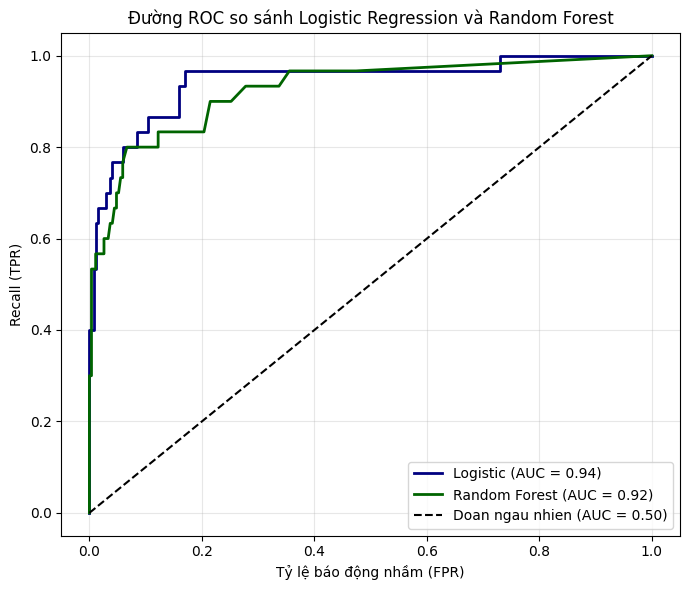

Nhan xet:
- Duong ROC cua ca hai mo hinh deu om sat goc tren ben trai, cho thay kha nang phan loai rat tot.
- O mot so doan, hai duong ROC co cat nhau vi RandomForest co the tot hon o mot so nguong cu the, nhung tong the AUC cua Logistic Regression van nhinh hon mot chut.


In [14]:
# CELL 10: BÀI TẬP 4 - Tự vẽ đường ROC cho Logistic và Random Forest, lưu 'roc.png'
rf = RandomForestClassifier(200, random_state=0)
rf.fit(X_tr, y_tr)
xs_rf = rf.predict_proba(X_te)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_te, xs)
fpr_rf, tpr_rf, _ = roc_curve(y_te, xs_rf)

auc_lr = roc_auc_score(y_te, xs)
auc_rf = roc_auc_score(y_te, xs_rf)

plt.figure(figsize=(7, 6))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic (AUC = {auc_lr:.2f})", color="navy", lw=2)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.2f})", color="darkgreen", lw=2)
plt.plot([0, 1], [0, 1], 'k--', label="Doan ngau nhien (AUC = 0.50)")
plt.title("Đường ROC so sánh Logistic Regression và Random Forest")
plt.xlabel("Tỷ lệ báo động nhầm (FPR)")
plt.ylabel("Recall (TPR)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("roc.png", dpi=150)
plt.show()

print("Nhan xet:")
print("- Duong ROC cua ca hai mo hinh deu om sat goc tren ben trai, cho thay kha nang phan loai rat tot.")
print("- O mot so doan, hai duong ROC co cat nhau vi RandomForest co the tot hon o mot so nguong cu the, nhung tong the AUC cua Logistic Regression van nhinh hon mot chut.")

In [15]:
# CELL 11: BÀI TẬP 5 - Thêm class_weight='balanced' cho RandomForest và SVC
rf_bal = RandomForestClassifier(200, class_weight="balanced", random_state=0)
svc_bal = make_pipeline(StandardScaler(), SVC(probability=True, class_weight="balanced", random_state=0))

print(f"{'Mo hinh':25s} | {'Precision':9s} | {'Recall':6s} | {'F1':6s}")
for ten, mh in [("Random Forest (Binh thuong)", rf),
                ("Random Forest (Can bang)", rf_bal),
                ("SVC (Binh thuong)", make_pipeline(StandardScaler(), SVC(probability=True, random_state=0))),
                ("SVC (Can bang)", svc_bal)]:
    mh.fit(X_tr, y_tr)
    du_m = mh.predict(X_te)
    print(f"{ten:25s} |   {precision_score(y_te, du_m):.4f}    | {recall_score(y_te, du_m):.4f} | {f1_score(y_te, du_m):.4f}")

print("\nNhan xet:")
print("- Khi bat class_weight='balanced', ca SVC va Random Forest deu tang vot recall (tim ra nhieu ban bo hoc hon) nhung precision giam xuong do so luong bao dong nham (FP) tang len.")

Mo hinh                   | Precision | Recall | F1    
Random Forest (Binh thuong) |   0.7727    | 0.5667 | 0.6538
Random Forest (Can bang)  |   0.7500    | 0.4000 | 0.5217
SVC (Binh thuong)         |   0.8824    | 0.5000 | 0.6383
SVC (Can bang)            |   0.4464    | 0.8333 | 0.5814

Nhan xet:
- Khi bat class_weight='balanced', ca SVC va Random Forest deu tang vot recall (tim ra nhieu ban bo hoc hon) nhung precision giam xuong do so luong bao dong nham (FP) tang len.


In [16]:
# CELL 12: BÀI TẬP 6 - MAE, RMSE và R2 trên giá nhà, thử nghiệm đoán hỏng 1 căn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df_nha = pd.read_csv("gia_nha.csv")
X_nha = df_nha.drop(columns="gia")
y_nha = df_nha["gia"]

X_tr_n, X_te_n, y_tr_n, y_te_n = train_test_split(X_nha, y_nha, test_size=0.25, random_state=17)

lr_nha = LinearRegression().fit(X_tr_n, y_tr_n)
y_pred = lr_nha.predict(X_te_n)

mae_1 = mean_absolute_error(y_te_n, y_pred)
rmse_1 = np.sqrt(mean_squared_error(y_te_n, y_pred))
r2_1 = r2_score(y_te_n, y_pred)

print("Truoc khi doan hong:")
print(f"  MAE  = {mae_1:.4f}")
print(f"  RMSE = {rmse_1:.4f}")
print(f"  R2   = {r2_1:.4f}\n")

# Cộng thêm 5 tỷ (5.0) vào dự đoán của đúng một căn đầu tiên trong tập kiểm tra
y_pred_hong = y_pred.copy()
y_pred_hong[0] += 5.0

mae_2 = mean_absolute_error(y_te_n, y_pred_hong)
rmse_2 = np.sqrt(mean_squared_error(y_te_n, y_pred_hong))
r2_2 = r2_score(y_te_n, y_pred_hong)

print("Sau khi doan hong 1 can (+5 ty):")
print(f"  MAE  = {mae_2:.4f} (tang {(mae_2 - mae_1):.4f})")
print(f"  RMSE = {rmse_2:.4f} (tang {(rmse_2 - rmse_1):.4f})")
print(f"  R2   = {r2_2:.4f}")

print("\nNhan xet & Giai thich:")
print("- RMSE thay doi (tang len) nhieu hon MAE khi co mot sai so lon.")
print("- Ly do: RMSE binh phuong sai so ((y_that - y_doan)^2) truoc khi lay can bac hai, nen no phat nang (phat rat nang) cac sai so lon (outliers), trong khi MAE chi dung gia tri tuyet đối tuyến tính.")

Truoc khi doan hong:
  MAE  = 0.2185
  RMSE = 0.2700
  R2   = 0.9759

Sau khi doan hong 1 can (+5 ty):
  MAE  = 0.5519 (tang 0.3333)
  RMSE = 1.4433 (tang 1.1733)
  R2   = 0.3110

Nhan xet & Giai thich:
- RMSE thay doi (tang len) nhieu hon MAE khi co mot sai so lon.
- Ly do: RMSE binh phuong sai so ((y_that - y_doan)^2) truoc khi lay can bac hai, nen no phat nang (phat rat nang) cac sai so lon (outliers), trong khi MAE chi dung gia tri tuyet đối tuyến tính.
